## Lab # 10: K-Means Clustering

### **Student Information**
- **Name**: Abdul Hayy Khan
- **Roll No**: 24F-AI-051

### Lab Tasks:

Task 1: Load a dataset (e.g., Mall Customer Segmentation).

In [27]:
# import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [28]:
# load mall customer dataset
data = pd.read_csv('../datasets/Mall_Customers.csv')

# display first five rows
print("First five rows:")
print(data.head())

First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [29]:
# display dataset information
print("Dataset shape:", data.shape)

Dataset shape: (200, 5)


In [30]:
# display column names
print("Column names:")
print(data.columns.tolist())

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [31]:
# check missing values
print("Missing values:")
print(data.isnull().sum())

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Task 2: Apply data preprocessing (normalize features if needed)

In [32]:
# select features for clustering
X = data[[
    "Annual Income (k$)",
    "Spending Score (1-100)"
]].copy()

In [33]:
# standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected features:")
print(X.head())

print("\nStandardized data shape:", X_scaled.shape)

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Standardized data shape: (200, 2)


Task 3: Determine the optimal number of clusters using Elbow Method 

In [ ]:
# calculate inertia for different K values
inertia_values = []

k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)r

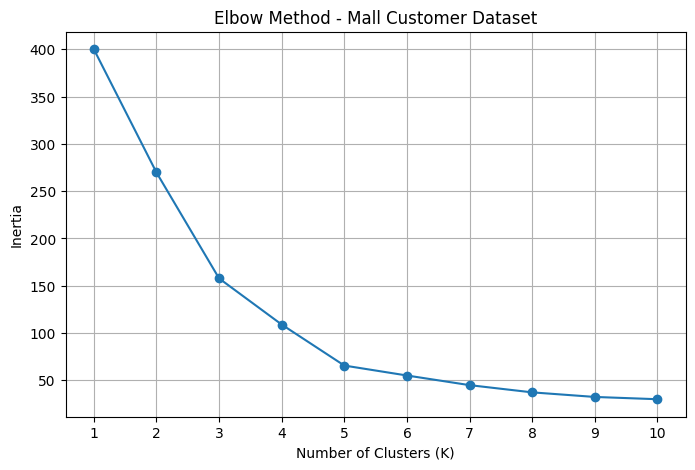

In [35]:
# plot elbow method
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method - Mall Customer Dataset")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)

plt.show()

Task 4: Implement K-Means clustering for the selected value of K.

In [36]:
# create K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

In [37]:
# train model and predict clusters
clusters = kmeans.fit_predict(X_scaled)

In [38]:
# add cluster labels to original dataset
data["Cluster"] = clusters

In [39]:
# display cluster assignments
print("Customer Cluster Assignments:")
print(data[[
    "CustomerID",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Cluster"
]].head(10))

Customer Cluster Assignments:
   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        4
1           2                  15                      81        2
2           3                  16                       6        4
3           4                  16                      77        2
4           5                  17                      40        4
5           6                  17                      76        2
6           7                  18                       6        4
7           8                  18                      94        2
8           9                  19                       3        4
9          10                  19                      72        2


In [40]:
# count customers in each cluster
print("Number of customers in each cluster:")
print(data["Cluster"].value_counts().sort_index())

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Task 5: Visualize the clusters in 2D or 3D (if the dataset has 2 or 3 features).

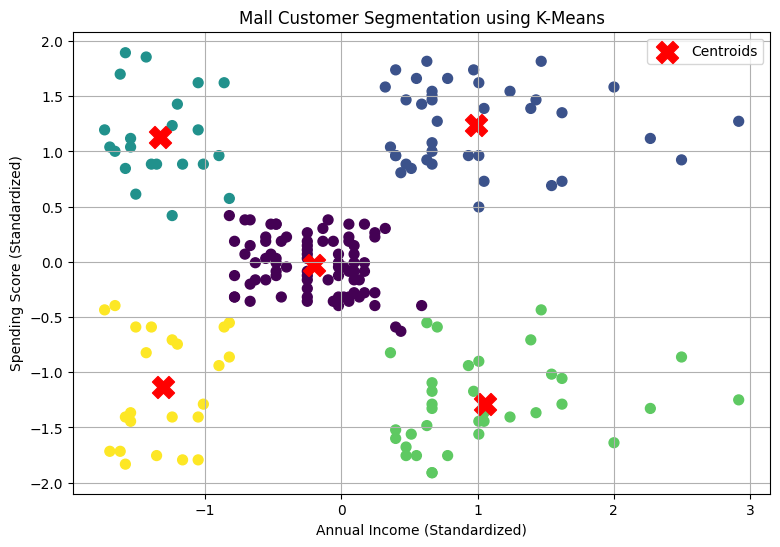

In [41]:
# plot customer clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

# plot cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.title("Mall Customer Segmentation using K-Means")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend()
plt.grid(True)

plt.show()

Task 6: Evaluate the clustering: Although K-Means is unsupervised, since the Iris dataset has labels, we can compare them.

In [42]:
# evaluate clustering performance
silhouette = silhouette_score(X_scaled, clusters)

print("K-Means Clustering Evaluation (Mall Customers)")
print("Number of Clusters:", kmeans.n_clusters)
print("Inertia:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(silhouette, 4))

K-Means Clustering Evaluation (Mall Customers)
Number of Clusters: 5
Inertia: 65.5684
Silhouette Score: 0.5547


In [ ]:
# evaluate clustering performance on Iris dataset
from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

iris_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
iris_clusters = iris_kmeans.fit_predict(X_iris)

ari = adjusted_rand_score(iris.target, iris_clusters)
print("Adjusted Rand Index:", round(ari, 4))   

# true species vs predicted cluster
print(pd.crosstab(iris.target, iris_clusters,
                  rownames=["True species"], colnames=["Cluster"]))

Adjusted Rand Index: 0.6201
Cluster        0   1   2
True species            
0              0  50   0
1             39   0  11
2             14   0  36


Task: Analyze Customer Segments

In [44]:
# calculate average values for each cluster
cluster_analysis = data.groupby("Cluster")[[
    "Annual Income (k$)",
    "Spending Score (1-100)"
]].mean()

print("Customer Segment Analysis:")
print(cluster_analysis.round(2))

Customer Segment Analysis:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91
